# **K-means**

**K-means (k-medias)** es un algoritmo de aprendizaje automático no supervisado que divide un conjunto de datos en k grupos o clústeres basándose en la similitud de sus características.

Su principal limitación es que el usuario debe definir el valor de k inicialmente.

Este algoritmo se usa cuando tenemos datos sin etiquetas. Por ejemplo, medidas de flores (largo de pétalo, ancho de pétalo) pero no se sabe qué tipos de flores son. Se quiere descubrir cuántos tipos de flores hay.

En realidad, sí se conocen las tres especies, que luego usaremos para comparar el resultado obtenido: Iris **setosa**, Iris **versicolor** e Iris **virginica**.

Esto es aprendizaje no supervisado: no hay una respuesta correcta.

In [ ]:
from sklearn.datasets import load_iris

iris = load_iris()
print(type(iris))

<class 'sklearn.utils._bunch.Bunch'>


In [ ]:
iris.feature_names
iris.target
iris.target_names
iris.DESCR

In [ ]:
datos = iris.data
print(type(datos))

<class 'numpy.ndarray'>


In [ ]:
# operaciones
primera_flor = datos[0]
primera_flor
un_valor = datos[5, 2]
un_valor
rango10a15 = datos[10:15]
rango10a15
rango0a3 = datos[:3]
rango0a3

In [ ]:
# se dispone de 150 datos, para cada uno 4 medidas
datos.shape

(150, 4)

In [ ]:
from sklearn.cluster import KMeans

# === este es el número de grupos ===
n_clusters = 3
# =====================================

# se configura el modelo
modelo = KMeans(n_clusters=n_clusters, random_state=0, n_init=10)
# se entrena el modelo
modelo.fit(datos)

KMeans(n_clusters=3, n_init=10, random_state=0)

In [ ]:
print(modelo.labels_)          # etiqueta de cluster (0, 1, 2...) de cada muestra
print(modelo.cluster_centers_) # coordenadas de los K centroides (shape: K × n_features)
print(modelo.inertia_)         # suma de distancias² (cómo de "compactos" son los clusters)
print(modelo.n_iter_)          # iteraciones que necesitó para converger

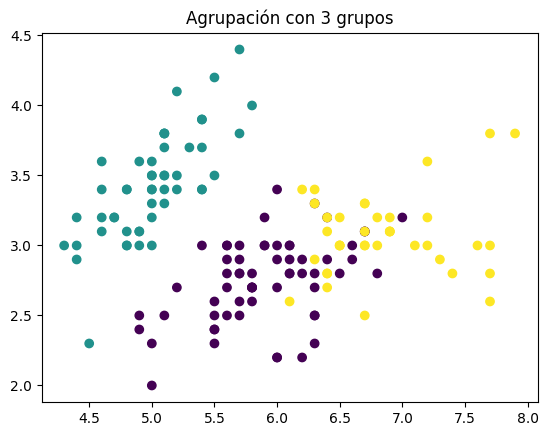

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(datos[:, 0], datos[:, 1], c=modelo.labels_, cmap="viridis")
plt.title(f"Agrupación con {n_clusters} grupos")
plt.show()

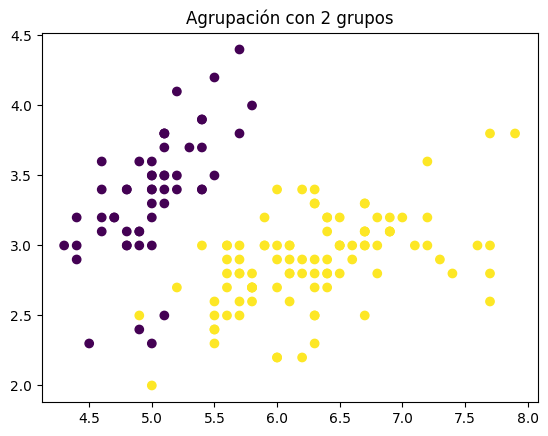

In [ ]:
# prueba el código con 2 grupos
modelo_2 = KMeans(n_clusters=2, random_state=0, n_init=10)
modelo_2.fit(datos)

plt.scatter(datos[:, 0], datos[:, 1], c=modelo_2.labels_, cmap="viridis")
plt.title("Agrupación con 2 grupos")
plt.show()

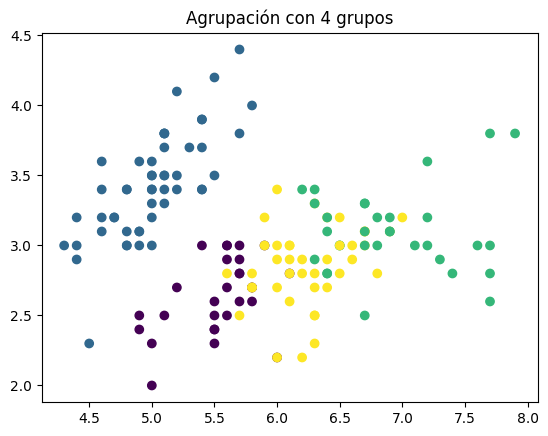

In [ ]:
# prueba el código con 4 grupos
modelo_4 = KMeans(n_clusters=4, random_state=0, n_init=10)
modelo_4.fit(datos)

plt.scatter(datos[:, 0], datos[:, 1], c=modelo_4.labels_, cmap="viridis")
plt.title("Agrupación con 4 grupos")
plt.show()

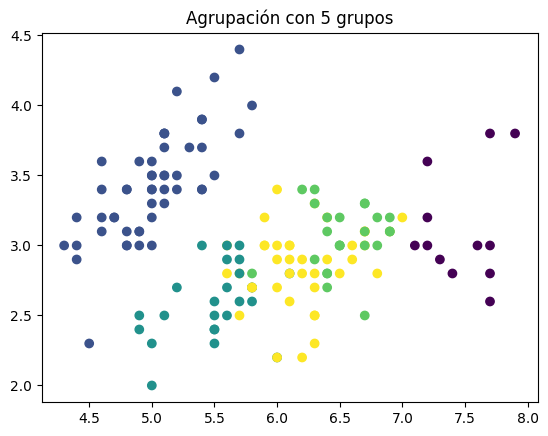

In [ ]:
# prueba el código con 5 grupos
modelo_5 = KMeans(n_clusters=5, random_state=0, n_init=10)
modelo_5.fit(datos)

plt.scatter(datos[:, 0], datos[:, 1], c=modelo_5.labels_, cmap="viridis")
plt.title("Agrupación con 5 grupos")
plt.show()

**K-Means sirve para datos sin etiquetar, ¿qué datos reales llegan sin etiquetar en el mundo profesional?**

Respuesta: En el mundo profesional, la gran mayoría de los datos en bruto carecen de etiquetas y se aprovechan mediante diversas técnicas de agrupación. Entre sus principales aplicaciones destaca la segmentación de clientes para estrategias de marketing dirigido, así como la detección de fraudes mediante la identificación de anomalías en transacciones bancarias o registros de red. Además, se utiliza en el procesamiento de lenguaje natural (NLP) para clasificar automáticamente grandes volúmenes de texto, como correos o noticias, y en el análisis avanzado de imágenes para interpretar fotografías satelitales o pruebas médicas.

El tipo de dato **numpy.ndarray** es un array de **NumPy**, para extraer fragmentos de datos debes usar coordenadas dentro de corchetes con la estructura:

datos[filas, columnas]

Los datos se pueden guardar en un array estructurado como si fuera una tabla de Excel con nombres en las columnas, lo ideal es transformarlo en un **DataFrame de Pandas**.


In [ ]:
import pandas as pd

tabla = pd.DataFrame(datos, columns=iris.feature_names)
print(tabla.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2


In [ ]:
# también se puede importar los datos directamente,
# pero así no se dispone de los nombres de las columnas
tabla2 = pd.DataFrame(datos)
print(tabla2.head())

     0    1    2    3
0  5.1  3.5  1.4  0.2
1  4.9  3.0  1.4  0.2
2  4.7  3.2  1.3  0.2
3  4.6  3.1  1.5  0.2
4  5.0  3.6  1.4  0.2


In [ ]:
tabla.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    int64  
 5   species_name       150 non-null    object 
 6   cluster            150 non-null    int32  
dtypes: float64(4), int32(1), int64(1), object(1)
memory usage: 7.7+ KB


In [ ]:
tabla.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species,cluster
count,150.000000,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000,0.840000
std,0.828066,0.435866,1.765298,0.762238,0.819232,0.803349
min,4.300000,2.000000,1.000000,0.100000,0.000000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000,1.750000
max,7.900000,4.400000,6.900000,2.500000,2.000000,2.000000


In [ ]:
tabla['petal length (cm)']

,petal length (cm)
0,1.4
1,1.4
2,1.3
3,1.5
4,1.4
...,...
145,5.2
146,5.0
147,5.2
148,5.4


In [ ]:
flores_grandes = tabla[tabla['petal length (cm)'] > 5]

In [ ]:
# aquí se agregan tres columnas que representan el código de la especie,
# el nombre de la especie a la tabla y el código del cluster asignado
tabla['species'] = iris.target
tabla['species_name'] = tabla['species'].map(lambda x: iris.target_names[x])
tabla['cluster'] = modelo.labels_

In [ ]:
tabla

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species,species_name,cluster
0,5.1,3.5,1.4,0.2,0,setosa,1
1,4.9,3.0,1.4,0.2,0,setosa,1
2,4.7,3.2,1.3,0.2,0,setosa,1
3,4.6,3.1,1.5,0.2,0,setosa,1
4,5.0,3.6,1.4,0.2,0,setosa,1
...,...,...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2,virginica,2
146,6.3,2.5,5.0,1.9,2,virginica,0
147,6.5,3.0,5.2,2.0,2,virginica,2
148,6.2,3.4,5.4,2.3,2,virginica,2


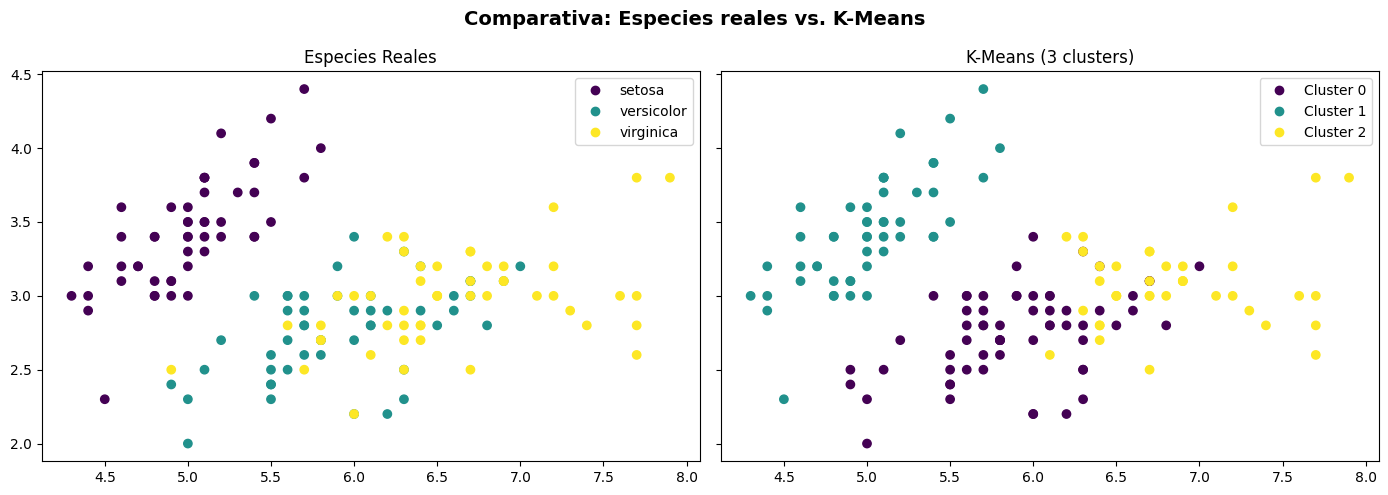

In [ ]:
# para comparar el resultado con las especies realesn_clusters = 3

# creamos una figura con 2 gráficos enfrentados (1 fila, 2 columnas)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

scatter1 = ax1.scatter(
    tabla['sepal length (cm)'],
    tabla['sepal width (cm)'],
    c=tabla['species'],
    cmap='viridis'
)
ax1.set_title("Especies Reales")
ax1.legend(handles=scatter1.legend_elements()[0], labels=list(iris.target_names))

scatter2 = ax2.scatter(
    tabla['sepal length (cm)'],
    tabla['sepal width (cm)'],
    c=tabla['cluster'],
    cmap='viridis'
)
ax2.set_title(f"K-Means ({n_clusters} clusters)")
ax2.legend(handles=scatter2.legend_elements()[0], labels=[f'Cluster {i}' for i in range(n_clusters)])

plt.suptitle("Comparativa: Especies reales vs. K-Means", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# para comparar el resultado con las especies reales
print(modelo.labels_)
print(iris.target)

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 0 2 2 2 2 2 0 2 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]


Implementa una comparación entre los resultados obtenidos y los resultados reales.

In [33]:
# aquí va la implementación
import numpy as np

cluster_map = {}
for cluster_id in range(3):

    especie_dominante = tabla[tabla['cluster'] == cluster_id]['species_name'].mode()[0]
    cluster_map[cluster_id] = especie_dominante

tabla['prediccion_nombre'] = tabla['cluster'].map(cluster_map)

print("=== ANÁLISIS DE ERROR POR ESPECIE ===")
for especie in iris.target_names:
    total = (tabla['species_name'] == especie).sum()
    correctos = ((tabla['species_name'] == especie) & (tabla['prediccion_nombre'] == especie)).sum()
    errores = total - correctos
    pct_error = (errores / total) * 100

    print(f"• {especie.capitalize()}:")
    print(f"  - Correctos: {correctos}/{total}")
    print(f"  - Errores: {errores}")
    print(f"  - Porcentaje de error: {pct_error:.2f}%\n")

print(f"La especie que presenta un mayor porcentaje de error es: {especie.capitalize()}")

=== ANÁLISIS DE ERROR POR ESPECIE ===
• Setosa:
  - Correctos: 50/50
  - Errores: 0
  - Porcentaje de error: 0.00%

• Versicolor:
  - Correctos: 48/50
  - Errores: 2
  - Porcentaje de error: 4.00%

• Virginica:
  - Correctos: 36/50
  - Errores: 14
  - Porcentaje de error: 28.00%

La especie que presenta un mayor porcentaje de error es: Virginica
